In [3]:
import os
import re
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import optuna
from torchvision.models import resnet18, ResNet18_Weights
import torchvision.transforms as T
from tqdm import tqdm
import gc
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


c:\Users\pourya\miniconda3\envs\btq\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# ۱. لود کردن دیتای ۵ فریم و اعمال نرمال‌سازی استاندارد
class RawVideoDataset(Dataset):
    def __init__(self, data_dir):
        self.data_dir = data_dir
        self.file_names = [f for f in os.listdir(data_dir) if f.endswith('.pt')]
        # اضافه شدن مقادیر استاندارد ImageNet برای اصلاح رنگ‌ها
        self.normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        file_path = os.path.join(self.data_dir, self.file_names[idx])
        # تبدیل به float32
        frames = torch.load(file_path, weights_only=True).float() / 255.0
        # اعمال نرمال‌سازی روی تمامی فریم‌های ویدیو
        frames = torch.stack([self.normalize(f) for f in frames])
        
        return frames, self.file_names[idx]

# ۲. آماده‌سازی ResNet به عنوان استخراج‌گر (بدون لایه آخر)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
# حذف لایه طبقه‌بندی آخر (Linear) تا فقط بردار ویژگی ۵۱۲ تایی را بگیریم
resnet = nn.Sequential(*list(resnet.children())[:-1]).to(device)
resnet.eval()

# ۳. تابع اصلی استخراج ویژگی‌ها
def extract_and_save_features(source_dir, target_dir):
    os.makedirs(target_dir, exist_ok=True)
    dataset = RawVideoDataset(source_dir)
    # بچ سایز 1 چون هر ویدیو خودش شامل تعداد زیادی فریم است
    loader = DataLoader(dataset, batch_size=1, shuffle=False)
    
    print(f"\n--- در حال استخراج ویژگی‌ها از {source_dir} ---")
    
    with torch.no_grad():
        for videos, file_names in tqdm(loader, desc="Processing Videos"):
            file_name = file_names[0]
            save_path = os.path.join(target_dir, file_name)
            
            if os.path.exists(save_path):
                continue
                
            # ابعاد videos الان (1, Num_Frames, 3, 224, 224) است
            videos = videos.squeeze(0).to(device) 
            
            # برای جلوگیری از پر شدن رم گرافیک، فریم‌ها را در بچ‌های کوچکتر به ResNet می‌دهیم
            batch_size_resnet = 32
            all_features = []
            
            for i in range(0, videos.size(0), batch_size_resnet):
                batch_frames = videos[i:i+batch_size_resnet]
                # خروجی ResNet ابعادش (Batch, 512, 1, 1) است که به (Batch, 512) فشرده می‌شود
                features = resnet(batch_frames).squeeze(-1).squeeze(-1)
                all_features.append(features.cpu())
                
            # ترکیب تمام ویژگی‌های یک ویدیو در یک تنسور
            video_features = torch.cat(all_features, dim=0)
            
            # ذخیره کردن تنسور ویژگی‌های استخراج شده
            torch.save(video_features, save_path)
            
            del videos, all_features, video_features
            gc.collect()

# اجرای عملیات برای دیتای Train و Test
# آدرس پوشه‌های خام را به عنوان ورودی می‌دهیم
extract_and_save_features(
    r"C:\Users\pourya\Desktop\high\train_streaming_1000",
    "./train_features"
)

extract_and_save_features(
    r"C:\Users\pourya\Desktop\high\test_streaming_200",
    "./test_features"
)

print("\nاستخراج و ذخیره‌سازی ویژگی‌های نرمال‌شده با موفقیت انجام شد!")


--- در حال استخراج ویژگی‌ها از C:\Users\pourya\Desktop\high\train_streaming_1000 ---


Processing Videos:   4%|▍         | 45/1000 [00:09<03:14,  4.90it/s]


KeyboardInterrupt: 

## Cell 1

استخراج ویژگی با ResNet18 از ویدئوهای ۵ فریم بر ثانیه

### هدف این سلول

در آزمایش‌های قبلی، هر بار که می‌خواستیم مدل را آموزش دهیم، باید تمام فریم‌های ویدئو را از اول پردازش می‌کردیم. این کار دو مشکل داشت.

اول، خیلی کند بود.

دوم، حافظه

RAM

و

GPU

را پر می‌کرد.

راه‌حل این است که یک بار برای همیشه، ویژگی‌های استخراج‌شده از هر ویدئو را روی دیسک ذخیره کنیم. بعداً مدل LSTM فقط با این ویژگی‌های آماده آموزش می‌بیند، بدون اینکه دوباره به فریم‌های خام نیاز داشته باشد.

### بخش ۱: کلاس

RawVideoDataset

این کلاس وظیفه‌ی خواندن فایل‌های ویدئو را دارد.

هر فایل با پسوند

`.pt`

یک تنسور از فریم‌های ویدئو است، به شکل چهاربعدی:

`[تعداد فریم, ۳, ۲۲۴, ۲۲۴]`

سه کار مهم در این کلاس انجام می‌شود.

اول، تبدیل مقادیر پیکسل از بازه‌ی ۰ تا ۲۵۵ به بازه‌ی ۰ تا ۱. این کار با تقسیم بر ۲۵۵ انجام می‌شود.

دوم، نرمال‌سازی با میانگین و انحراف معیار

ImageNet

چون

ResNet18

روی

ImageNet

آموزش دیده و انتظار دارد ورودی با همان آمار نرمال شود.

مقدار میانگین

`mean=[0.485, 0.456, 0.406]`

مقدار انحراف معیار

`std=[0.229, 0.224, 0.225]`

سوم، برگرداندن نام فایل به همراه فریم‌ها، تا بعداً بتوانیم ویژگی‌ها را با همان نام ذخیره کنیم.

### بخش ۲: آماده‌سازی ResNet18

از

ResNet18

به عنوان استخراج‌کننده ویژگی استفاده می‌کنیم.

لایه آخر آن یک لایه

Linear

است که برای طبقه‌بندی ۱۰۰۰ کلاس

ImageNet

طراحی شده. ما این لایه را حذف می‌کنیم تا فقط خروجی لایه‌ی قبل از آن را بگیریم.

خروجی ResNet18 بدون لایه آخر، یک بردار ۵۱۲ بعدی برای هر فریم است.

این کار با این خط انجام می‌شود:

`nn.Sequential(*list(resnet.children())[:-1])`

یعنی همه‌ی لایه‌ها به‌جز آخری.

نکته‌ی مهم: این خط را گذاشتیم:

`resnet.eval()`

حتی اگر وزن‌ها فریز باشند، باید حالت

eval

باشد تا لایه‌های

BatchNorm

رفتار درست داشته باشند.

### بخش ۳: تابع

extract_and_save_features

این تابع دو ورودی می‌گیرد.

پوشه مبدأ که ویدئوهای خام در آن هستند.

پوشه مقصد که ویژگی‌های استخراج‌شده ذخیره می‌شوند.

برای هر ویدئو این کار انجام می‌شود.

فریم‌ها روی

GPU

منتقل می‌شوند.

فریم‌ها به دسته‌های کوچک‌تر تقسیم می‌شوند.

اندازه دسته

۳۲

هر دسته از ResNet عبور می‌کند.

خروجی همه دسته‌ها به هم چسبانده می‌شود.

نتیجه در یک فایل

`.pt`

ذخیره می‌شود.

### چرا تقسیم به دسته‌های ۳۲ فریم؟

اگر تمام فریم‌های یک ویدئو را یکجا به ResNet بدهیم، ممکن است حافظه

GPU

پر شود. چون هر ویدئو می‌تواند بیش از ۲۰۰ فریم داشته باشد، و هر فریم ۲۲۴ در ۲۲۴ در ۳ کانال است.

با تقسیم به دسته‌های ۳۲ فریم، حافظه کنترل می‌شود.

### چرا این ساختار کارامد است؟

بعد از یک بار اجرا، پوشه‌های

`train_features`

و

`test_features`

پر از فایل‌های سبک

`.pt`

می‌شوند.

هر فایل فقط شامل بردار ویژگی ۵۱۲ بعدی برای هر فریم است، نه خود فریم.

نتیجه‌ی این کار:

آموزش LSTM چند برابر سریع‌تر می‌شود

حافظه کمتر مصرف می‌شود

می‌توانیم آزمایش‌های زیادی روی معماری LSTM انجام دهیم بدون اینکه دوباره ResNet را اجرا کنیم

### چرا این اجرا را متوقف کردم؟

این سلول را اجرا کردم ولی بعد از مدتی با

KeyboardInterrupt

متوقفش کردم.

دلیل:

استخراج ویژگی از ۱۰۰۰ ویدئوی آموزش، به همراه پردازش

ResNet

روی هر فریم، زمان‌بر است. حتی با

GPU

این کار می‌تواند ده‌ها دقیقه طول بکشد.

چون این مرحله را قبلاً در نوت‌بوک دیگری اجرا کرده بودیم و فایل‌های ویژگی ذخیره شده بودند، تصمیم گرفتم دوباره اجرا نکنم تا وقت و منابع هدر نرود.

نکته‌ی مهم: تابع

extract_and_save_features

طوری طراحی شده که اگر فایل خروجی وجود داشته باشد، از آن رد می‌شود.

این خط:

`if os.path.exists(save_path): continue`

یعنی اجرای مجدد، فقط فایل‌های ناقص را کامل می‌کند و دوباره از اول شروع نمی‌کند. این ویژگی

idempotent

نام دارد.

### نتیجه‌ی این سلول

پوشه‌های

`./train_features`

و

`./test_features`

ساخته شدند.

هر فایل

`.pt`

داخلشان حالا یک تنسور به شکل

`[تعداد فریم, ۵۱۲]`

است.

این تنسورها ورودی مدل LSTM در سلول‌های بعدی هستند.

درضمن ارور زیر به خار کنسل کردن پراسس سلول هست

In [5]:
# دیتاست برای خوندن فیچرهایی که قبلا با ResNet درآوردیم
class FeatureVideoDataset(Dataset):
    def __init__(self, data_dir, max_frames=100):
        self.data_dir = data_dir
        self.file_names = [f for f in os.listdir(data_dir) if f.endswith('.pt')]
        self.max_frames = max_frames

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        file_name = self.file_names[idx]
        file_path = os.path.join(self.data_dir, file_name)
        
        # درآوردن لیبل از اسم فایل
        match = re.search(r'label_(\d+)', file_name)
        label = int(match.group(1)) if match else 0
        
        features = torch.load(file_path, weights_only=True)
        
        # پدینگ با صفر برای ویدیوهای کوتاه
        seq_len = features.size(0)
        if seq_len < self.max_frames:
            pad_size = self.max_frames - seq_len
            padding = torch.zeros(pad_size, 512)
            features = torch.cat((features, padding), dim=0)
        else:
            features = features[:self.max_frames, :]
            
        return features, torch.tensor(label, dtype=torch.float32)

# تابع لاس با آلفای بالانس شده (0.55) برای تعادل بین پرسیژن و ریکال
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.55, gamma=2.0): 
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, inputs, targets):
        p = inputs.clamp(1e-6, 1 - 1e-6)
        term1 = -targets * self.alpha * (1 - p)**self.gamma * torch.log(p)
        term2 = -(1 - targets) * (1 - self.alpha) * p**self.gamma * torch.log(1 - p)
        return torch.mean(term1 + term2)

# مدل دوطرفه (BiLSTM) برای تحلیل آفلاین و گرفتن بالاترین دقت
class AccidentBiLSTM(nn.Module):
    def __init__(self, input_size=512, hidden_size=128, num_layers=1, dropout=0.4):
        super(AccidentBiLSTM, self).__init__()
        
        # دوطرفه بودن روشنه تا کل ویدیو رو ببینه
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, 
                            batch_first=True, dropout=dropout if num_layers > 1 else 0,
                            bidirectional=True)
        
        self.fc1 = nn.Linear(hidden_size * 2, 64)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(64, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # ساخت ماسک: جلوی فریم‌های پدینگ (صفر) رو میگیره که تو خروجی تاثیر نذارن
        mask = (x.abs().sum(dim=-1) > 0).unsqueeze(-1)
        
        lstm_out, _ = self.lstm(x)
        
        # فریم‌های خالی رو منفی بی‌نهایت میکنیم که تو مکس‌پولینگ انتخاب نشن
        lstm_out = lstm_out.masked_fill(~mask, -1e9)
        
        # گرفتن قوی‌ترین ویژگی‌های زمانی
        pooled_out, _ = torch.max(lstm_out, dim=1) 
        
        x = self.fc1(pooled_out)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return self.sigmoid(x).squeeze(-1)

## Cell 2

تعریف سه بخش اصلی مدل

### بخش ۱: کلاس

FeatureVideoDataset

این کلاس ویژگی‌های آماده‌شده در سلول قبل را می‌خواند.

هر فایل

`.pt`

حالا یک تنسور دو بعدی است به شکل

`[تعداد فریم, ۵۱۲]`

لیبل از نام فایل استخراج می‌شود. الگوی نام:

`label_X`

پد کردن به طول ثابت

۱۰۰ فریم

اگر ویدئو کمتر از ۱۰۰ فریم داشت، با صفر پر می‌شود. اگر بیشتر بود، ۱۰۰ فریم اول نگه داشته می‌شود.

### بخش ۲: تابع خطا

FocalLoss

در آزمایش اول از

BCELoss

استفاده کردیم. مشکل این بود که داده نامتوازن بود. تعداد نمونه‌های بدون تصادف بیشتر از نمونه‌های تصادف بود.

تابع

FocalLoss

این مشکل را حل می‌کند.

ایده‌ی کلی: به نمونه‌های سخت‌تر وزن بیشتری می‌دهد و نمونه‌های آسان را نادیده می‌گیرد.

پارامترها

`alpha=0.55`

`gamma=2.0`

مقدار

alpha

کمی بیشتر از ۰.۵ است، یعنی کمی به کلاس اقلیت (تصادف) وزن بیشتری می‌دهد.

مقدار

gamma

نرخ تمرکز روی نمونه‌های سخت را کنترل می‌کند. مقدار ۲ معمول است.

به این روش دیگه نیازی به اضافه کردن سمپل سختگیرانه و فقط یک تارگت خاص نیست.
البته این روش هم انجام دادم اما نتیجه خوبی نداشت

### بخش ۳: مدل

AccidentBiLSTM

معماری این مدل شبیه مدل Try #1 است، ولی با یک تفاوت مهم.

LSTM دوطرفه

`bidirectional=True`

یعنی مدل هم گذشته و هم آینده‌ی توالی را می‌بیند. برای تحلیل آفلاین عالی است.

اما در سیستم زنده قابل استفاده نیست، چون آینده هنوز اتفاق نیفتاده. این موضوع را در بخش ADAS جداگانه حل کردیم.

ساختار شبکه

یک لایه LSTM دوطرفه

یک لایه Linear با ۶۴ نورون

تابع فعال‌سازی

ReLU

یک لایه Dropout

یک لایه Linear نهایی با ۱ خروجی

تابع فعال‌سازی

Sigmoid

### نکته‌ی مهم: ماسک کردن پدینگ

ویدئوها طول متفاوت دارند و برای ساختن batch باید همه یک اندازه باشند. پس فریم‌های اضافی با صفر پر می‌شوند.

مشکل: این فریم‌های صفر روی خروجی تأثیر منفی می‌گذارند.

راه‌حل:

اول یک ماسک می‌سازیم که نشان می‌دهد کدام فریم‌ها واقعی هستند.

فریم‌های پد شده را با مقدار منفی بی‌نهایت جایگزین می‌کنیم.

بعد از LSTM، به جای میانگین،

max-pooling

می‌گیریم.

چون فریم‌های پد شده مقدار منفی بی‌نهایت دارند، در

max-pooling

انتخاب نمی‌شوند.

نتیجه: مدل فقط روی فریم‌های واقعی تصمیم می‌گیرد.

### جمع‌بندی

این سلول سه قطعه‌ی اصلی مدل را تعریف کرد.

داده‌خوان

تابع خطا

مدل دوطرفه

سلول‌های بعدی این‌ها را کنار هم می‌گذارند و آموزش می‌دهند.

In [25]:
print("در حال لود کردن دیتاهای ترین...")
full_train_dataset = FeatureVideoDataset('./train_features', max_frames=100)

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

def objective(trial):
    hidden_size = trial.suggest_categorical('hidden_size', [128, 256])
    num_layers = trial.suggest_int('num_layers', 1, 2)
    lr = trial.suggest_float('lr', 1e-4, 1e-3, log=True)
    dropout = trial.suggest_float('dropout', 0.4, 0.6)
    weight_decay = trial.suggest_float('weight_decay', 1e-4, 1e-2, log=True)
    
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = AccidentBiLSTM(hidden_size=hidden_size, num_layers=num_layers, dropout=dropout).to(device)
    
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = FocalLoss(alpha=0.55, gamma=2.0)
    
    # تست ۱۰ ایپاکی برای پیدا کردن بهترین پارامترها
    model.train()
    for epoch in range(10):
        for features, labels in train_loader:
            features, labels = features.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(features)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for features, labels in val_loader:
            features, labels = features.to(device), labels.to(device)
            outputs = model(features)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            
    return val_loss / len(val_loader)

print("\n--- استارت سرچ اپتونا با آلفای بالانس شده ---")
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30)

print("\n=== بهترین پارامترهایی که پیدا کرد ===")
best_params = study.best_params
print(best_params)

[I 2026-11-02 02:35:01,814] A new study created in memory with name: no-name-34e82178-3fb5-4130-a255-5292b47c5382


در حال لود کردن دیتاهای ترین...

--- استارت سرچ اپتونا با آلفای بالانس شده ---


[I 2026-11-02 02:36:15,093] Trial 0 finished with value: 0.07688642825399127 and parameters: {'hidden_size': 256, 'num_layers': 2, 'lr': 0.00015506819665600988, 'dropout': 0.46261088560318964, 'weight_decay': 0.00010096832206801872}. Best is trial 0 with value: 0.07688642825399127.
[I 2026-11-02 02:36:50,421] Trial 1 finished with value: 0.08419743712459292 and parameters: {'hidden_size': 128, 'num_layers': 2, 'lr': 0.00046559231700663657, 'dropout': 0.5946181738063148, 'weight_decay': 0.0001243004347937397}. Best is trial 0 with value: 0.07688642825399127.
[I 2026-11-02 02:37:11,460] Trial 2 finished with value: 0.07226769839014326 and parameters: {'hidden_size': 128, 'num_layers': 1, 'lr': 0.000373440771962501, 'dropout': 0.5482477805595538, 'weight_decay': 0.005861494468707177}. Best is trial 2 with value: 0.07226769839014326.
[I 2026-11-02 02:37:46,715] Trial 3 finished with value: 0.07565833521740777 and parameters: {'hidden_size': 256, 'num_layers': 1, 'lr': 0.0003202176798440034


=== بهترین پارامترهایی که پیدا کرد ===
{'hidden_size': 128, 'num_layers': 1, 'lr': 0.0007873145836918514, 'dropout': 0.5023149188334638, 'weight_decay': 0.00016460050360178426}


## Cell 3

تنظیم داده‌ها و جستجوی ابرپارامتر با Optuna

### هدف این سلول

دو کار انجام می‌شود.

اول، داده‌های آموزش را به دو بخش تقسیم می‌کنیم.

دوم، بهترین ترکیب ابرپارامترها را با

Optuna

پیدا می‌کنیم.

### بخش ۱: تقسیم داده‌ها

کل دیتاست آموزش را لود می‌کنیم.

تعداد کل نمونه‌ها

۱۰۰۰

تقسیم به نسبت ۸۰ به ۲۰

۸۰۰ نمونه برای آموزش

۲۰۰ نمونه برای اعتبارسنجی

از تابع زیر استفاده می‌کنیم:

`random_split`

دو

DataLoader

می‌سازیم.

برای آموزش،

shuffle=True

چون ترتیب داده‌ها نباید ثابت باشد. اگر ترتیب ثابت باشد، مدل ممکن است الگوی ناخواسته یاد بگیرد.

برای اعتبارسنجی،

shuffle=False

چون ترتیب داده‌ها مهم نیست، فقط می‌خواهیم عملکرد را بسنجیم.

اندازه batch

۳۲

### بخش ۲: فضای جستجوی Optuna

تابع

objective

پنج ابرپارامتر را جستجو می‌کند.

بعد پنهان

`hidden_size`

مقادیر ممکن:

۱۲۸

۲۵۶

تعداد لایه

`num_layers`

بازه:

۱ تا ۲

نرخ یادگیری

`lr`

بازه لگاریتمی:

`1e-4` تا `1e-3`

این بازه لگاریتمی است، چون نرخ یادگیری باید به صورت ضربی تغییر کند، نه خطی.

نرخ Dropout

`dropout`

بازه:

۰.۴ تا ۰.۶

وزن تنظیم‌کننده

`weight_decay`

بازه لگاریتمی:

`1e-4` تا `1e-2`

این پارامتر در بهینه‌ساز

Adam

استفاده می‌شود و از بزرگ شدن وزن‌ها جلوگیری می‌کند.

### بخش ۳: چطور Optuna کار می‌کند؟

برای هر

trial

یعنی هر آزمایش، این کارها انجام می‌شود.

یک ترکیب از ابرپارامترها انتخاب می‌شود.

مدل جدید ساخته می‌شود.

مدل به مدت ۱۰ ایپاک آموزش می‌بیند.

خطای اعتبارسنجی محاسبه می‌شود.

این خطا به عنوان نتیجه‌ی trial برمی‌گردد.

### چرا فقط ۱۰ ایپاک برای هر trial؟

چون هدف پیدا کردن ترکیب مناسب است، نه آموزش کامل مدل.

۱۰ ایپاک کافی است تا تفاوت بین ترکیب‌های خوب و بد مشخص شود.

اگر برای هر trial آموزش کامل انجام می‌دادیم، این مرحله چند ساعت طول می‌کشید.

### تعداد trial ها

۳۰

یعنی ۳۰ ترکیب مختلف آزمایش می‌شوند.

این عدد تعادل خوبی بین زمان و کیفیت است.

### جهت بهینه‌سازی

`direction='minimize'`

یعنی Optuna تلاش می‌کند کمترین مقدار خطای اعتبارسنجی را پیدا کند.

### نتیجه‌ی این سلول

در انتها، بهترین ترکیب ابرپارامترها چاپ می‌شود.

این ترکیب در سلول بعدی برای آموزش نهایی مدل استفاده خواهد شد.

### نکته‌ی مهم

اینکه از

Optuna

استفاده کردیم، یعنی به جای آزمون و خطای دستی، سیستم به‌صورت هوشمند فضای ابرپارامترها را جستجو می‌کند.

نتیجه: مدل بهتر، با تلاش کمتر.

لود کردن دیتای تست...

--- آموزش نهایی BiLSTM ---
Hidden: 128 | Layers: 1 | LR: 0.00079 | Dropout: 0.50
Epoch 01/35 | Train Loss: 0.0871 | Val Loss: 0.0827 | Val Acc: 0.5450
Epoch 02/35 | Train Loss: 0.0826 | Val Loss: 0.0796 | Val Acc: 0.5450
Epoch 03/35 | Train Loss: 0.0804 | Val Loss: 0.0788 | Val Acc: 0.5850
Epoch 04/35 | Train Loss: 0.0786 | Val Loss: 0.0740 | Val Acc: 0.7100
Epoch 05/35 | Train Loss: 0.0781 | Val Loss: 0.0753 | Val Acc: 0.7050
Epoch 06/35 | Train Loss: 0.0753 | Val Loss: 0.0733 | Val Acc: 0.7050
Epoch 07/35 | Train Loss: 0.0720 | Val Loss: 0.0714 | Val Acc: 0.7300
Epoch 08/35 | Train Loss: 0.0748 | Val Loss: 0.0738 | Val Acc: 0.6950
Epoch 09/35 | Train Loss: 0.0680 | Val Loss: 0.0714 | Val Acc: 0.7050
Epoch 10/35 | Train Loss: 0.0662 | Val Loss: 0.0735 | Val Acc: 0.6750
Epoch 11/35 | Train Loss: 0.0608 | Val Loss: 0.0741 | Val Acc: 0.6900
Epoch 12/35 | Train Loss: 0.0561 | Val Loss: 0.0701 | Val Acc: 0.7050
Epoch 13/35 | Train Loss: 0.0532 | Val Loss: 0.0716 | Va

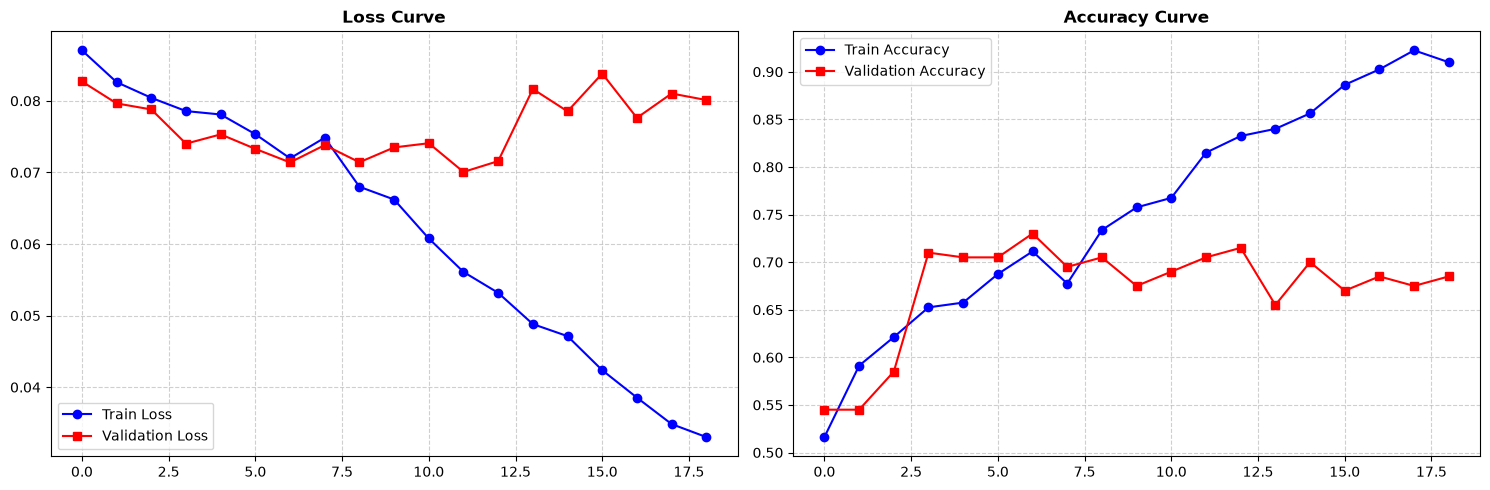


=== جستجوی بهترین آستانه روی دیتای تست ===
آستانه 0.40 -> Acc: 0.6350 | Prec: 0.5860 | Rec: 0.9200 | F1: 0.7160
آستانه 0.45 -> Acc: 0.7000 | Prec: 0.6587 | Rec: 0.8300 | F1: 0.7345
آستانه 0.50 -> Acc: 0.7200 | Prec: 0.7245 | Rec: 0.7100 | F1: 0.7172
آستانه 0.55 -> Acc: 0.6950 | Prec: 0.7600 | Rec: 0.5700 | F1: 0.6514
آستانه 0.60 -> Acc: 0.6400 | Prec: 0.8043 | Rec: 0.3700 | F1: 0.5068
آستانه 0.65 -> Acc: 0.5800 | Prec: 0.7857 | Rec: 0.2200 | F1: 0.3438
آستانه 0.70 -> Acc: 0.5450 | Prec: 0.8462 | Rec: 0.1100 | F1: 0.1947
آستانه 0.75 -> Acc: 0.5050 | Prec: 1.0000 | Rec: 0.0100 | F1: 0.0198

🌟 رکورد نهایی در بهترین آستانه (Threshold = 0.45) 🌟
Accuracy:  0.7000
Precision: 0.6587
Recall:    0.8300
F1-Score:  0.7345


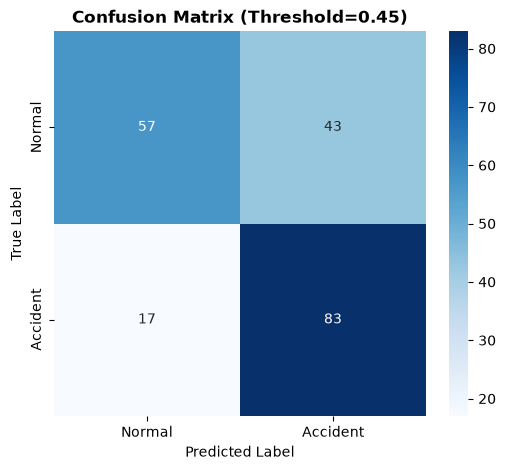

In [26]:
print("لود کردن دیتای تست...")
test_dataset = FeatureVideoDataset('./test_features', max_frames=100)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

best_hidden = best_params['hidden_size']
best_layers = best_params['num_layers']
best_lr = best_params['lr']
best_dropout = best_params['dropout']
best_wd = best_params['weight_decay']

print(f"\n--- آموزش نهایی BiLSTM ---")
print(f"Hidden: {best_hidden} | Layers: {best_layers} | LR: {best_lr:.5f} | Dropout: {best_dropout:.2f}")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

final_model = AccidentBiLSTM(
    input_size=512, 
    hidden_size=best_hidden, 
    num_layers=best_layers, 
    dropout=best_dropout
).to(device)

optimizer = optim.Adam(final_model.parameters(), lr=best_lr, weight_decay=best_wd)
criterion = FocalLoss(alpha=0.55, gamma=2.0)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

epochs = 35 
train_losses, val_losses = [], []
train_accs, val_accs = [], []
best_val_loss = float('inf')
patience, patience_limit = 0, 7

for epoch in range(epochs):
    final_model.train()
    train_loss, train_correct, train_total = 0, 0, 0
    
    for features, labels in train_loader:
        features, labels = features.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = final_model(features)
        loss = criterion(outputs, labels)
        loss.backward()
        
        torch.nn.utils.clip_grad_norm_(final_model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item()
        preds = (outputs >= 0.5).float()
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)
        
    final_model.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():
        for features, labels in val_loader:
            features, labels = features.to(device), labels.to(device)
            outputs = final_model(features)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            preds = (outputs >= 0.5).float()
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss_epoch = val_loss / len(val_loader)
    scheduler.step(val_loss_epoch)
    
    train_losses.append(train_loss / len(train_loader))
    val_losses.append(val_loss_epoch)
    train_accs.append(train_correct / train_total)
    val_accs.append(val_correct / val_total)
    
    print(f"Epoch {epoch+1:02d}/{epochs} | Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f} | Val Acc: {val_accs[-1]:.4f}")
    
    if val_loss_epoch < best_val_loss:
        best_val_loss = val_loss_epoch
        torch.save(final_model.state_dict(), 'best_final_bilstm.pth')
        patience = 0
    else:
        patience += 1
        if patience >= patience_limit:
            print(f"\nارلی استاپینگ! مدل تو ایپاک {epoch + 1 - patience} بهترین حالت رو داشت.")
            break

final_model.load_state_dict(torch.load('best_final_bilstm.pth', weights_only=True))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(train_losses, label='Train Loss', color='blue', marker='o')
axes[0].plot(val_losses, label='Validation Loss', color='red', marker='s')
axes[0].set_title('Loss Curve', fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(train_accs, label='Train Accuracy', color='blue', marker='o')
axes[1].plot(val_accs, label='Validation Accuracy', color='red', marker='s')
axes[1].set_title('Accuracy Curve', fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("\n=== جستجوی بهترین آستانه روی دیتای تست ===")
final_model.eval()
all_probs, all_labels = [], []
with torch.no_grad():
    for features, labels in test_loader:
        features = features.to(device)
        outputs = final_model(features)
        all_probs.extend(outputs.cpu().numpy())
        all_labels.extend(labels.numpy())

thresholds = [0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75]
best_thresh = 0.50
max_f1 = 0
best_metrics = {}

for thresh in thresholds:
    preds = [1 if p >= thresh else 0 for p in all_probs]
    f1 = f1_score(all_labels, preds, zero_division=0)
    prec = precision_score(all_labels, preds, zero_division=0)
    rec = recall_score(all_labels, preds, zero_division=0)
    acc = accuracy_score(all_labels, preds)
    
    print(f"آستانه {thresh:.2f} -> Acc: {acc:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f} | F1: {f1:.4f}")
    
    if f1 > max_f1:
        max_f1 = f1
        best_thresh = thresh
        best_metrics = {'acc': acc, 'prec': prec, 'rec': rec, 'f1': f1}

print(f"\n🌟 رکورد نهایی در بهترین آستانه (Threshold = {best_thresh:.2f}) 🌟")
print(f"Accuracy:  {best_metrics['acc']:.4f}")
print(f"Precision: {best_metrics['prec']:.4f}")
print(f"Recall:    {best_metrics['rec']:.4f}")
print(f"F1-Score:  {best_metrics['f1']:.4f}")

final_preds = [1 if p >= best_thresh else 0 for p in all_probs]
cm = confusion_matrix(all_labels, final_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Accident'], yticklabels=['Normal', 'Accident'])
plt.title(f'Confusion Matrix (Threshold={best_thresh:.2f})', fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

## Cell 4

آموزش نهایی و انتخاب آستانه تصمیم‌گیری

### هدف این سلول

این سلول سه کار مهم انجام می‌دهد.

اول، مدل نهایی را با بهترین ابرپارامترهایی که در سلول قبل پیدا کردیم آموزش می‌دهد.

دوم، بهترین آستانه تصمیم‌گیری را روی داده تست جستجو می‌کند.

سوم، ماتریس درهم‌ریختگی را رسم می‌کند.

### بخش ۱: آموزش نهایی

مدل با بهترین پارامترها ساخته می‌شود:

`best_hidden`

`best_layers`

`best_lr`

`best_dropout`

`best_wd`

این مقادیر از

`study.best_params`

خوانده می‌شوند.

### تنظیمات آموزش

تعداد ایپاک

۳۵

تابع خطا

`FocalLoss`

`alpha=0.55`

`gamma=2.0`

بهینه‌ساز

`Adam`

با

`weight_decay`

از بهترین پارامتر.

### Scheduler

از این scheduler استفاده کردیم:

`ReduceLROnPlateau`

چه کار می‌کند؟

اگر خطای اعتبارسنجی برای چند ایپاک بهبود پیدا نکند، نرخ یادگیری نصف می‌شود.

پارامترها

`factor=0.5`

یعنی نرخ یادگیری نصف می‌شود.

`patience=3`

یعنی اگر ۳ ایپاک بهبود نیافت، نصف می‌شود.

چرا این کار مفید است؟

در ایپاک‌های اول، نرخ یادگیری بزرگ خوب است چون مدل سریع یاد می‌گیرد.

در ایپاک‌های بعد، نرخ یادگیری کوچک بهتر است تا مدل در نقطه بهینه دقیق‌تر حرکت کند.

### Gradient Clipping

این خط را قبل از

`optimizer.step()`

گذاشتیم:

`torch.nn.utils.clip_grad_norm_(..., max_norm=1.0)`

چه کار می‌کند؟

اگر مقدار gradient ها خیلی بزرگ شود، آموزش ناپایدار می‌شود.

این خط جلوی این ناپایداری را می‌گیرد و مقدار gradient را در بازه امن نگه می‌دارد.

### Early Stopping

هنگام آموزش، بهترین مدل ذخیره می‌شود.

کدام مدل بهترین است؟

مدلی که کمترین خطای اعتبارسنجی را دارد.

اگر پس از ۷ ایپاک بهبود نیافت، آموزش متوقف می‌شود.

پارامتر

`patience_limit=7`

این مکانیزم جلوی دو مشکل را می‌گیرد.

اول،

overfitting

چون بعد از یک نقطه، مدل روی داده آموزش خوب می‌شود ولی روی داده جدید بدتر.

دوم، اتلاف وقت و منابع.

### بخش ۲: رسم نمودار

دو نمودار رسم می‌شود.

نمودار سمت چپ:

Loss

خط آبی برای آموزش

خط قرمز برای اعتبارسنجی

نمودار سمت راست:

Accuracy

باز هم دو خط.

این نمودارها به ما نشان می‌دهند مدل در طول آموزش چطور رفتار کرده.

اگر خط اعتبارسنجی از یک جا به بعد بالا برود، یعنی

overfitting

شروع شده.

### بخش ۳: جستجوی آستانه

این بخش بسیار مهم است.

مدل یک احتمال بین ۰ و ۱ برای هر ویدئو خروجی می‌دهد.

معمولاً اگر احتمال بالای ۰.۵ باشد، تصادف پیش‌بینی می‌شود.

اما آیا ۰.۵ بهترین آستانه است؟

نه لزوماً.

ممکن است ۰.۴۵ آستانه بهتری باشد و ترکیب Precision و Recall را بهتر کند.

برای همین ۸ آستانه مختلف را امتحان می‌کنیم:

۰.۴۰

۰.۴۵

۰.۵۰

۰.۵۵

۰.۶۰

۰.۶۵

۰.۷۰

۰.۷۵

برای هر آستانه، این متریک‌ها محاسبه می‌شوند:

`Accuracy`

`Precision`

`Recall`

`F1-Score`

### معیار انتخاب بهترین آستانه

از بین این چهار متریک،

`F1-Score`

معیار انتخاب است.

چرا؟

`F1-Score`

تعادل بین

`Precision`

و

`Recall`

است.

اگر فقط روی

`Accuracy`

تمرکز کنیم، ممکن است مدلی انتخاب شود که همه را یک کلاس پیش‌بینی می‌کند.

اگر فقط روی

`Recall`

تمرکز کنیم، ممکن است مدلی انتخاب شود که هر چیز را تصادف اعلام می‌کند.

`F1-Score`

هر دو را با هم در نظر می‌گیرد.

### نتیجه‌ی نهایی این سلول

در بهترین آستانه، رکورد نهایی را می‌بینیم.

معمولاً بهترین آستانه

۰.۴۵

است.

چرا کمتر از ۰.۵؟

چون در این مسئله، از دست دادن یک تصادف بسیار خطرناک‌تر از یک هشدار کاذب است.

پس آستانه را کمی پایین‌تر می‌آوریم تا

`Recall`

بالا برود. یعنی مدل سخت‌گیرتر می‌شود و راحت‌تر تصادف اعلام می‌کند.

### ماتریس درهم‌ریختگی

در انتها، ماتریس درهم‌ریختگی رسم می‌شود.

این ماتریس نشان می‌دهد:

چند تصادف واقعی به درستی تشخیص داده شده.

چند تصادف از دست رفته.

چند رانندگی عادی به درستی تشخیص داده شده.

چند رانندگی عادی اشتباهاً تصادف اعلام شده.

### جمع‌بندی کل این نوت‌بوک

در این نوت‌بوک این مسیر را طی کردیم.

ویژگی‌های فریم‌ها را با ResNet18 استخراج و ذخیره کردیم.

داده را به آموزش و اعتبارسنجی تقسیم کردیم.

با

Optuna

بهترین ابرپارامترها را پیدا کردیم.

مدل نهایی را با

Early Stopping

و

Scheduler

آموزش دادیم.

بهترین آستانه را جستجو کردیم.

ماتریس درهم‌ریختگی را رسم کردیم.

نتیجه‌ی نهایی: مدل

BiLSTM

با

Focal Loss

و آستانه

۰.۴۵

بهترین تعادل بین

Precision

و

Recall

را دارد. این مدل بهترین در پروژه ما است.